# Machine Learning: Unit 1 | Complete Code
**Foundations of Machine Learning**: workflow, types of ML, data, Pandas, cleaning, EDA, visualization.

Run cells top to bottom. Install if needed: `pip install numpy pandas matplotlib seaborn scipy scikit-learn openpyxl`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings; warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.0.2 | numpy 2.4.4


## 1. Introduction & ML Workflow (mini end-to-end demo)
Steps: collect → clean → EDA → split → train → evaluate → predict.

In [2]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# 1. Collect
iris = load_iris(as_frame=True)
df_iris = iris.frame
# 2. Clean / 3. EDA (quick look)
print(df_iris.isnull().sum().sum(), "missing values")
print(df_iris.describe().round(2))
# 4. Split
X = df_iris.drop("target", axis=1); y = df_iris["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
# 5. Train
model = LogisticRegression(max_iter=500).fit(X_train, y_train)
# 6. Evaluate
print("Test accuracy:", accuracy_score(y_test, model.predict(X_test)))
# 7. Predict on new data
print("Prediction:", iris.target_names[model.predict([[5.1, 3.5, 1.4, 0.2]])[0]])

0 missing values
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count             150.00            150.00             150.00   
mean                5.84              3.06               3.76   
std                 0.83              0.44               1.77   
min                 4.30              2.00               1.00   
25%                 5.10              2.80               1.60   
50%                 5.80              3.00               4.35   
75%                 6.40              3.30               5.10   
max                 7.90              4.40               6.90   

       petal width (cm)  target  
count            150.00  150.00  
mean               1.20    1.00  
std                0.76    0.82  
min                0.10    0.00  
25%                0.30    0.00  
50%                1.30    1.00  
75%                1.80    2.00  
max                2.50    2.00  
Test accuracy: 0.9666666666666667
Prediction: setosa


## 2. Types of Machine Learning

### 2.1 Supervised learning (labeled data)

In [3]:
from sklearn.linear_model import LinearRegression
hours = np.array([[1],[2],[3],[4],[5]]); marks = np.array([35, 45, 55, 65, 75])
reg = LinearRegression().fit(hours, marks)            # features + labels
print("Predicted marks for 6 hours:", reg.predict([[6]])[0])

Predicted marks for 6 hours: 85.0


### 2.2 Unsupervised learning (no labels): clustering

Cluster sizes: [62 50 38]


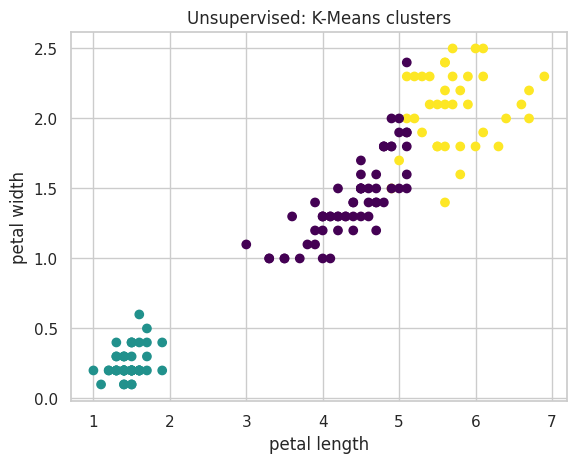

In [4]:
from sklearn.cluster import KMeans
Xu = load_iris().data                                  # we ignore the labels
km = KMeans(n_clusters=3, n_init=10, random_state=42).fit(Xu)
print("Cluster sizes:", np.bincount(km.labels_))
plt.scatter(Xu[:, 2], Xu[:, 3], c=km.labels_, cmap="viridis")
plt.xlabel("petal length"); plt.ylabel("petal width"); plt.title("Unsupervised: K-Means clusters"); plt.show()

### 2.3 Semi-supervised learning (few labels + many unlabeled)

In [5]:
from sklearn.semi_supervised import SelfTrainingClassifier
from sklearn.svm import SVC

Xs, ys = load_iris(return_X_y=True)
rng = np.random.RandomState(42)
y_semi = ys.copy()
y_semi[rng.rand(len(ys)) < 0.8] = -1                   # hide 80% of labels (-1 = unlabeled)
print("Labeled samples:", (y_semi != -1).sum(), "| Unlabeled:", (y_semi == -1).sum())

semi = SelfTrainingClassifier(SVC(probability=True, gamma="auto"))
semi.fit(Xs, y_semi)
print("Accuracy against true labels:", semi.score(Xs, ys))

Labeled samples: 31 | Unlabeled: 119
Accuracy against true labels: 0.9666666666666667


## 3. Understanding Data: Structured vs Unstructured

In [6]:
# Structured: rows & columns with fixed schema
structured = pd.DataFrame({"id": [1, 2], "name": ["Amit", "Riya"], "marks": [85, 90]})
print(structured)

# Semi-structured: JSON
import json
js = '{"id": 1, "name": "Amit", "subjects": ["ML", "DBMS"], "address": {"city": "Delhi"}}'
record = json.loads(js); print(record["address"]["city"], record["subjects"])
print(pd.json_normalize(record))                       # flatten JSON to table

# Unstructured: free text → convert to numbers (bag of words)
from sklearn.feature_extraction.text import CountVectorizer
texts = ["machine learning is fun", "learning python is fun"]
cv = CountVectorizer(); bow = cv.fit_transform(texts)
print(pd.DataFrame(bow.toarray(), columns=cv.get_feature_names_out()))

   id  name  marks
0   1  Amit     85
1   2  Riya     90
Delhi ['ML', 'DBMS']
   id  name    subjects address.city
0   1  Amit  [ML, DBMS]        Delhi
   fun  is  learning  machine  python
0    1   1         1        1       0
1    1   1         1        0       1


In [7]:
# Feature types in a DataFrame
people = pd.DataFrame({"age": [21, 25, 30], "height": [170.5, 160.2, 180.1],
                       "city": ["Delhi", "Pune", "Goa"],
                       "level": pd.Categorical(["low", "high", "medium"],
                                               categories=["low", "medium", "high"], ordered=True)})
print(people.dtypes)
print("Numeric:", people.select_dtypes(include="number").columns.tolist())
print("Categorical:", people.select_dtypes(exclude="number").columns.tolist())

age          int64
height     float64
city           str
level     category
dtype: object
Numeric: ['age', 'height']
Categorical: ['city', 'level']


## 4. Data Loading & Basic Operations with Pandas

### 4.1 Creating Series and DataFrame

In [8]:
s = pd.Series([10, 20, 30], index=["a", "b", "c"]); print(s, "\n")

data = {"Name": ["Amit", "Riya", "Sam", "Neha", "Karan"],
        "Age":  [21, 22, np.nan, 23, 22],
        "Marks":[85, 90, 78, 92, 66],
        "City": ["Delhi", "Pune", "Delhi", "Goa", "Pune"]}
df = pd.DataFrame(data); df

a    10
b    20
c    30
dtype: int64 



,Name,Age,Marks,City
0,Amit,21.0,85,Delhi
1,Riya,22.0,90,Pune
2,Sam,NaN,78,Delhi
3,Neha,23.0,92,Goa
4,Karan,22.0,66,Pune


### 4.2 Saving & loading (CSV, JSON, Excel)

In [9]:
df.to_csv("students.csv", index=False)
df.to_json("students.json", orient="records")
try:
    df.to_excel("students.xlsx", index=False)          # needs openpyxl
    print(pd.read_excel("students.xlsx", sheet_name="Sheet1").shape, "rows,cols from Excel")
except Exception as e:
    print("Excel skipped:", e)

df_csv  = pd.read_csv("students.csv")
df_part = pd.read_csv("students.csv", usecols=["Name", "Marks"], nrows=3)
df_json = pd.read_json("students.json")
print(df_csv.shape, df_part.shape, df_json.shape)
# From a database:  pd.read_sql("SELECT * FROM t", connection)

(5, 4) rows,cols from Excel


(5, 4) (3, 2) (5, 4)


### 4.3 Inspecting data

In [10]:
print(df.head(3)); print(df.tail(2))
print("shape:", df.shape, "| size:", df.size, "| ndim:", df.ndim)
print(df.columns.tolist()); print(df.dtypes)
df.info()
print(df.describe())
print(df.describe(include="object"))
print(df.nunique()); print(df["City"].unique()); print(df["City"].value_counts())
print(df.sample(2, random_state=1))

   Name   Age  Marks   City
0  Amit  21.0     85  Delhi
1  Riya  22.0     90   Pune
2   Sam   NaN     78  Delhi
    Name   Age  Marks  City
3   Neha  23.0     92   Goa
4  Karan  22.0     66  Pune
shape: (5, 4) | size: 20 | ndim: 2
['Name', 'Age', 'Marks', 'City']
Name         str
Age      float64
Marks      int64
City         str
dtype: object


<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Name    5 non-null      str    
 1   Age     4 non-null      float64
 2   Marks   5 non-null      int64  
 3   City    5 non-null      str    
dtypes: float64(1), int64(1), str(2)
memory usage: 292.0 bytes
             Age      Marks
count   4.000000   5.000000
mean   22.000000  82.200000
std     0.816497  10.545141
min    21.000000  66.000000
25%    21.750000  78.000000
50%    22.000000  85.000000
75%    22.250000  90.000000
max    23.000000  92.000000
        Name   City
count      5      5
unique     5      3
top     Amit  Delhi
freq       1      2
Name     5
Age      3
Marks    5
City     3
dtype: int64
<StringArray>
['Delhi', 'Pune', 'Goa']
Length: 3, dtype: str
City
Delhi    2
Pune     2
Goa      1
Name: count, dtype: int64
   Name   Age  Marks   City
2   Sam   NaN     78  Delhi
1  Riya  22.0     90   Pune


### 4.4 Selecting & filtering

In [11]:
print(df["Marks"].head(2))                           # Series
print(df[["Name", "Marks"]].head(2))                 # DataFrame
print(df.loc[0:2, ["Name", "Age"]])                  # label-based (end inclusive)
print(df.iloc[0:2, 0:2])                             # position-based (end exclusive)
print(df[df["Marks"] > 80])
print(df[(df["Marks"] > 80) & (df["City"] == "Delhi")])          # AND
print(df[(df["City"] == "Goa") | (df["City"] == "Pune")])        # OR
print(df[df["City"].isin(["Delhi", "Goa"])])
print(df.query("Marks > 80 and City == 'Delhi'"))

0    85
1    90
Name: Marks, dtype: int64
   Name  Marks
0  Amit     85
1  Riya     90
   Name   Age
0  Amit  21.0
1  Riya  22.0
2   Sam   NaN
   Name   Age
0  Amit  21.0
1  Riya  22.0
   Name   Age  Marks   City
0  Amit  21.0     85  Delhi
1  Riya  22.0     90   Pune
3  Neha  23.0     92    Goa
   Name   Age  Marks   City
0  Amit  21.0     85  Delhi
    Name   Age  Marks  City
1   Riya  22.0     90  Pune
3   Neha  23.0     92   Goa
4  Karan  22.0     66  Pune
   Name   Age  Marks   City
0  Amit  21.0     85  Delhi
2   Sam   NaN     78  Delhi
3  Neha  23.0     92    Goa
   Name   Age  Marks   City
0  Amit  21.0     85  Delhi


### 4.5 Modifying data

In [12]:
d = df.copy()
d["Grade"] = np.where(d["Marks"] >= 90, "A", "B")                  # new column
d["Marks"] = d["Marks"] + 5
d.rename(columns={"Marks": "Score"}, inplace=True)
d["Age"] = d["Age"].astype("float")
d["City"] = d["City"].str.lower().str.strip()
d["Double"] = d["Score"].apply(lambda x: x * 2)
d.drop(columns=["Double"], inplace=True)                           # drop column
d.drop(index=[0, 1], inplace=True)                                 # drop rows
d.reset_index(drop=True, inplace=True)
d

,Name,Age,Score,City,Grade
0,Sam,NaN,83,delhi,B
1,Neha,23.0,97,goa,A
2,Karan,22.0,71,pune,B


### 4.6 Sorting, grouping, aggregation, pivot, merging

In [13]:
print(df.sort_values("Marks", ascending=False))
print(df.sort_values(["City", "Marks"], ascending=[True, False]))
print(df.groupby("City")["Marks"].mean())
print(df.groupby("City").agg({"Marks": ["mean", "max"], "Age": "min"}))
print(df.pivot_table(values="Marks", index="City", aggfunc="mean"))
df["Grade"] = np.where(df["Marks"] >= 90, "A", "B")
print(pd.crosstab(df["City"], df["Grade"]))

# Combining DataFrames
d1 = pd.DataFrame({"ID": [1, 2, 3], "Name": ["A", "B", "C"]})
d2 = pd.DataFrame({"ID": [2, 3, 4], "Score": [80, 90, 70]})
print(pd.concat([d1, d1], axis=0))                       # stack rows
for how in ["inner", "left", "right", "outer"]:
    print(how, "join:\n", pd.merge(d1, d2, on="ID", how=how))

    Name   Age  Marks   City
3   Neha  23.0     92    Goa
1   Riya  22.0     90   Pune
0   Amit  21.0     85  Delhi
2    Sam   NaN     78  Delhi
4  Karan  22.0     66   Pune
    Name   Age  Marks   City
0   Amit  21.0     85  Delhi
2    Sam   NaN     78  Delhi
3   Neha  23.0     92    Goa
1   Riya  22.0     90   Pune
4  Karan  22.0     66   Pune
City
Delhi    81.5
Goa      92.0
Pune     78.0
Name: Marks, dtype: float64
      Marks       Age
       mean max   min
City                 
Delhi  81.5  85  21.0
Goa    92.0  92  23.0
Pune   78.0  90  22.0
       Marks
City        
Delhi   81.5
Goa     92.0
Pune    78.0
Grade  A  B
City       
Delhi  0  2
Goa    1  0
Pune   1  1
   ID Name
0   1    A
1   2    B
2   3    C
0   1    A
1   2    B
2   3    C
inner join:
    ID Name  Score
0   2    B     80
1   3    C     90
left join:
    ID Name  Score
0   1    A    NaN
1   2    B   80.0
2   3    C   90.0
right join:
    ID Name  Score
0   2    B     80
1   3    C     90
2   4  NaN     70
outer j

## 5. Data Cleaning

Create a deliberately messy dataset (missing values, outliers, duplicates).

In [14]:
rng = np.random.RandomState(0); n = 200
messy = pd.DataFrame({"age": rng.normal(35, 8, n).round(),
                      "salary": rng.normal(50000, 10000, n).round(),
                      "city": rng.choice(["Delhi", "Pune", "Goa"], n)})
messy.loc[rng.choice(n, 15, replace=False), "age"] = np.nan
messy.loc[rng.choice(n, 10, replace=False), "city"] = np.nan
messy.loc[[5, 50, 120], "salary"] = [250000, 300000, -5000]      # outliers
messy = pd.concat([messy, messy.iloc[:5]], ignore_index=True)    # 5 duplicates
print(messy.shape); messy.head()

(205, 3)


,age,salary,city
0,49.0,46308.0,Pune
1,38.0,47606.0,Delhi
2,43.0,60997.0,Goa
3,53.0,56553.0,Pune
4,50.0,56401.0,Delhi


### 5.1 Missing values

age       15
salary     0
city      10
dtype: int64
age       7.32
salary    0.00
city      4.88
dtype: float64


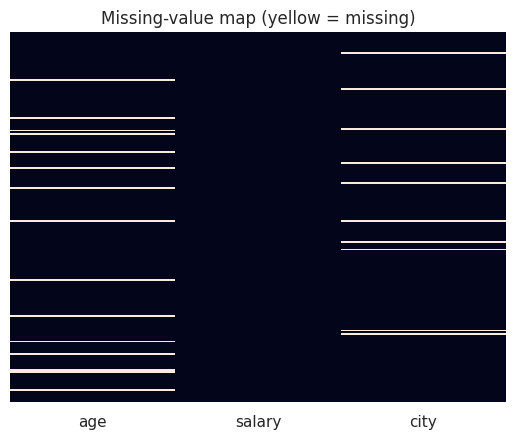

In [15]:
print(messy.isnull().sum())
print((messy.isnull().mean() * 100).round(2))
sns.heatmap(messy.isnull(), cbar=False, yticklabels=False); plt.title("Missing-value map (yellow = missing)"); plt.show()

In [16]:
# --- Dropping ---
print("dropna()          ->", messy.dropna().shape)
print("dropna(how='all') ->", messy.dropna(how="all").shape)
print("subset=['age']    ->", messy.dropna(subset=["age"]).shape)
print("thresh (cols >=95% filled) ->", messy.dropna(axis=1, thresh=int(0.95 * len(messy))).shape)

# --- Imputing with pandas ---
m = messy.copy()
m["age"] = m["age"].fillna(m["age"].median())             # numeric: median (robust)
m["city"] = m["city"].fillna(m["city"].mode()[0])         # categorical: mode
print(m.isnull().sum().sum(), "missing after fillna")

# --- Time-series style fills & interpolation ---
ts = pd.Series([1, np.nan, np.nan, 4, np.nan, 6])
print(ts.ffill().tolist(), ts.bfill().tolist(), ts.interpolate().tolist())

dropna()          -> (181, 3)
dropna(how='all') -> (205, 3)
subset=['age']    -> (190, 3)
thresh (cols >=95% filled) -> (205, 2)
0 missing after fillna
[1.0, 1.0, 1.0, 4.0, 4.0, 6.0] [1.0, 4.0, 4.0, 4.0, 6.0, 6.0] [1.0, 2.0, 3.0, 4.0, 5.0, 6.0]


In [17]:
# --- sklearn imputers (fit on TRAIN only to avoid data leakage) ---
from sklearn.impute import SimpleImputer, KNNImputer
train, test = messy.iloc[:150].copy(), messy.iloc[150:].copy()

imp = SimpleImputer(strategy="median")                    # mean / median / most_frequent / constant
train[["age"]] = imp.fit_transform(train[["age"]])        # learn median on train
test[["age"]]  = imp.transform(test[["age"]])             # reuse on test
print("Learned median age:", imp.statistics_)

knn_imp = KNNImputer(n_neighbors=3)
nums = messy[["age", "salary"]]
filled = pd.DataFrame(knn_imp.fit_transform(nums), columns=nums.columns)
print("KNN-imputed missing:", filled.isnull().sum().sum())

Learned median age: [36.]
KNN-imputed missing: 0


### 5.2 Outliers: detect & treat

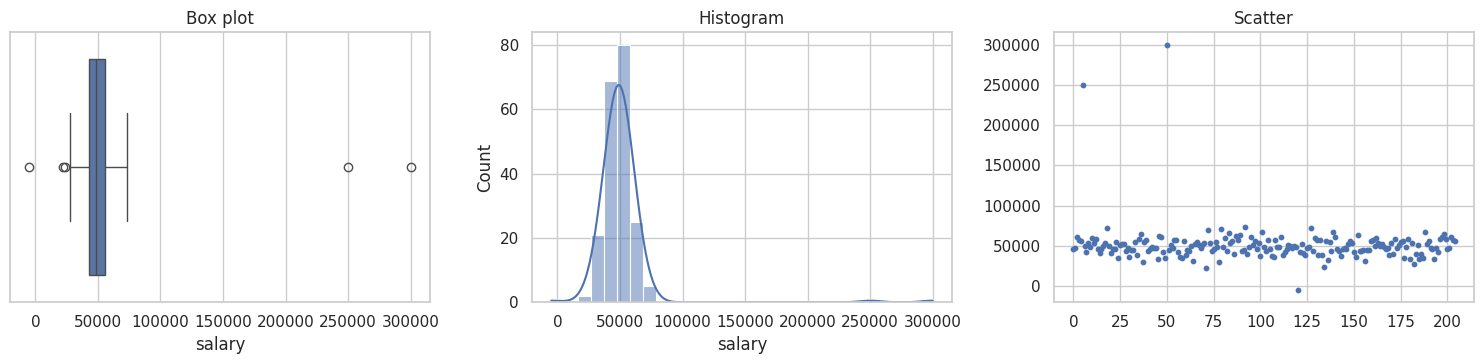

Z-score outliers:
       salary
5   250000.0
50  300000.0
Q1=43160 Q3=56063 IQR=12903  fences=(23806, 75418)
IQR outliers:
        salary
5    250000.0
50   300000.0
71    22274.0
120   -5000.0
134   23408.0


In [18]:
sal = messy["salary"]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
sns.boxplot(x=sal, ax=ax[0]); ax[0].set_title("Box plot")
sns.histplot(sal, kde=True, ax=ax[1]); ax[1].set_title("Histogram")
ax[2].scatter(range(len(sal)), sal, s=10); ax[2].set_title("Scatter"); plt.tight_layout(); plt.show()

# --- Z-score method (|z| > 3) ---
z = np.abs(stats.zscore(sal))
print("Z-score outliers:\n", messy[z > 3][["salary"]])

# --- IQR method ---
Q1, Q3 = sal.quantile(0.25), sal.quantile(0.75)
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
print(f"Q1={Q1:.0f} Q3={Q3:.0f} IQR={IQR:.0f}  fences=({lower:.0f}, {upper:.0f})")
print("IQR outliers:\n", messy[(sal < lower) | (sal > upper)][["salary"]])

In [19]:
# --- Treatment ---
# 1. Remove
removed = messy[(sal >= lower) & (sal <= upper)]
# 2. Cap (winsorize)
capped = messy.copy(); capped["salary"] = capped["salary"].clip(lower, upper)
# 3. Log transform (reduces right skew)
logged = np.log1p(messy["salary"].clip(lower=0))
# 4. Replace by median
rep = messy.copy(); rep.loc[(sal < lower) | (sal > upper), "salary"] = sal.median()

print("original", messy.shape, "| removed", removed.shape)
print("max salary: original", sal.max(), "-> capped", capped["salary"].max())
print("skew before:", round(sal.skew(), 2), "| after removal:", round(removed["salary"].skew(), 2))

# Worked example from notes
ex = pd.Series([2, 4, 5, 6, 7, 8, 40])
q1, q3 = ex.quantile([.25, .75]); i = q3 - q1
print("Fences:", q1 - 1.5 * i, q3 + 1.5 * i, "-> outlier:", ex[(ex < q1 - 1.5*i) | (ex > q3 + 1.5*i)].tolist())

original (205, 3) | removed (200, 3)
max salary: original 300000.0 -> capped 75417.5
skew before: 7.68 | after removal: 0.13
Fences: 0.0 12.0 -> outlier: [40]


### 5.3 Duplicates

In [20]:
print("Duplicate rows:", messy.duplicated().sum())
print(messy[messy.duplicated(keep=False)].sort_values(["age", "salary"]).head(6))
dedup = messy.drop_duplicates()
print("After drop_duplicates:", dedup.shape)
print("By subset:", messy.drop_duplicates(subset=["age", "salary"], keep="last").shape)

Duplicate rows: 5
      age   salary   city
1    38.0  47606.0  Delhi
201  38.0  47606.0  Delhi
2    43.0  60997.0    Goa
202  43.0  60997.0    Goa
0    49.0  46308.0   Pune
200  49.0  46308.0   Pune
After drop_duplicates: (200, 3)
By subset: (200, 3)


### 5.4 Other cleaning tasks (types, text, labels)

In [21]:
raw = pd.DataFrame({"Date": ["2026-01-05", "2026-02-10", "bad"],
                    "Price": ["100", "250.5", "abc"],
                    "City ": [" delhi", "PUNE ", "Goa"],
                    "Gender": ["M", "F", "M"]})
raw["Date"] = pd.to_datetime(raw["Date"], errors="coerce")          # invalid -> NaT
raw["Price"] = pd.to_numeric(raw["Price"], errors="coerce")         # invalid -> NaN
raw["City "] = raw["City "].str.strip().str.title()
raw["Gender"] = raw["Gender"].replace({"M": "Male", "F": "Female"})
raw.columns = raw.columns.str.strip().str.lower().str.replace(" ", "_")
print(raw); print(raw.dtypes)

# Validity check: impossible values
ages = pd.Series([25, -3, 150, 40]); print("Invalid ages:", ages[(ages < 0) | (ages > 120)].tolist())

        date  price   city  gender
0 2026-01-05  100.0  Delhi    Male
1 2026-02-10  250.5   Pune  Female
2        NaT    NaN    Goa    Male
date      datetime64[us]
price            float64
city                 str
gender               str
dtype: object
Invalid ages: [-3, 150]


## 6. Exploratory Data Analysis (EDA): Statistical Techniques

In [22]:
col = df_iris["sepal length (cm)"]
print("Mean:", col.mean(), "| Median:", col.median(), "| Mode:", col.mode()[0])
print("Range:", col.max() - col.min(), "| Variance:", col.var(), "| Std:", col.std())
print("Q1, Q3, IQR:", col.quantile(.25), col.quantile(.75), col.quantile(.75) - col.quantile(.25))
print("Coef. of variation (%):", col.std() / col.mean() * 100)
print("Skewness:", col.skew(), "| Kurtosis:", col.kurt())
print(col.agg(["mean", "median", "std", "var", "min", "max"]))

# Mean vs median with an outlier
d = pd.Series([3, 5, 7, 9, 100]); print("mean =", d.mean(), "| median =", d.median())

Mean: 5.843333333333334 | Median: 5.8 | Mode: 5.0
Range: 3.6000000000000005 | Variance: 0.6856935123042507 | Std: 0.828066127977863
Q1, Q3, IQR: 5.1 6.4 1.3000000000000007
Coef. of variation (%): 14.171125977944033
Skewness: 0.3149109566369728 | Kurtosis: -0.5520640413156395
mean      5.843333
median    5.800000
std       0.828066
var       0.685694
min       4.300000
max       7.900000
Name: sepal length (cm), dtype: float64
mean = 24.8 | median = 7.0


In [23]:
# Five-number summary + categorical frequencies
print(col.describe())
print(df_iris["target"].value_counts(normalize=True))

# Bivariate: correlation (Pearson & Spearman)
print(df_iris.corr().round(2))
print(df_iris.corr(method="spearman").round(2))
r, p = stats.pearsonr(df_iris["petal length (cm)"], df_iris["petal width (cm)"])
print(f"Pearson r = {r:.3f}, p-value = {p:.2e}")
print(df_iris.groupby("target").mean().round(2))                # group comparison

# Multicollinearity flag (|r| > 0.8)
c = df_iris.drop(columns="target").corr().abs()
print("Highly correlated pairs:", [(a, b) for a in c for b in c if a < b and c.loc[a, b] > 0.8])

count    150.000000
mean       5.843333
std        0.828066
min        4.300000
25%        5.100000
50%        5.800000
75%        6.400000
max        7.900000
Name: sepal length (cm), dtype: float64
target
0    0.333333
1    0.333333
2    0.333333
Name: proportion, dtype: float64
                   sepal length (cm)  sepal width (cm)  petal length (cm)  \
sepal length (cm)               1.00             -0.12               0.87   
sepal width (cm)               -0.12              1.00              -0.43   
petal length (cm)               0.87             -0.43               1.00   
petal width (cm)                0.82             -0.37               0.96   
target                          0.78             -0.43               0.95   

                   petal width (cm)  target  
sepal length (cm)              0.82    0.78  
sepal width (cm)              -0.37   -0.43  
petal length (cm)              0.96    0.95  
petal width (cm)               1.00    0.96  
target                   

In [24]:
# Hypothesis tests
g1 = df_iris[df_iris.target == 0]["petal length (cm)"]
g2 = df_iris[df_iris.target == 1]["petal length (cm)"]
t, p = stats.ttest_ind(g1, g2)
print(f"t-test: t={t:.2f}, p={p:.2e} ->", "significant" if p < 0.05 else "not significant")

# Chi-square test of association between two categorical variables
band = pd.cut(messy["salary"], bins=[-1e9, 45000, 55000, 1e9], labels=["low", "mid", "high"])
table = pd.crosstab(messy["city"], band)
chi2, p, dof, expected = stats.chi2_contingency(table)
print(table); print(f"chi2={chi2:.2f}, dof={dof}, p={p:.3f}")

# Normality check
print("Shapiro-Wilk (sepal length):", stats.shapiro(col))

t-test: t=-39.49, p=5.40e-62 -> significant
salary  low  mid  high
city                  
Delhi    21   30    13
Goa      21   25    19
Pune     20   25    21
chi2=2.60, dof=4, p=0.626
Shapiro-Wilk (sepal length): ShapiroResult(statistic=np.float64(0.9760902723490532), pvalue=np.float64(0.010181161454691156))


## 7. Data Visualization: Matplotlib

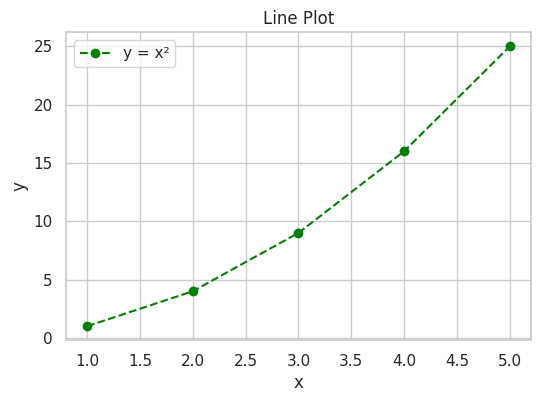

In [25]:
x = np.arange(1, 6); y = x ** 2

plt.figure(figsize=(6, 4))
plt.plot(x, y, color="green", linestyle="--", marker="o", label="y = x²")
plt.title("Line Plot"); plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.grid(True)
plt.savefig("line.png", dpi=150); plt.show()

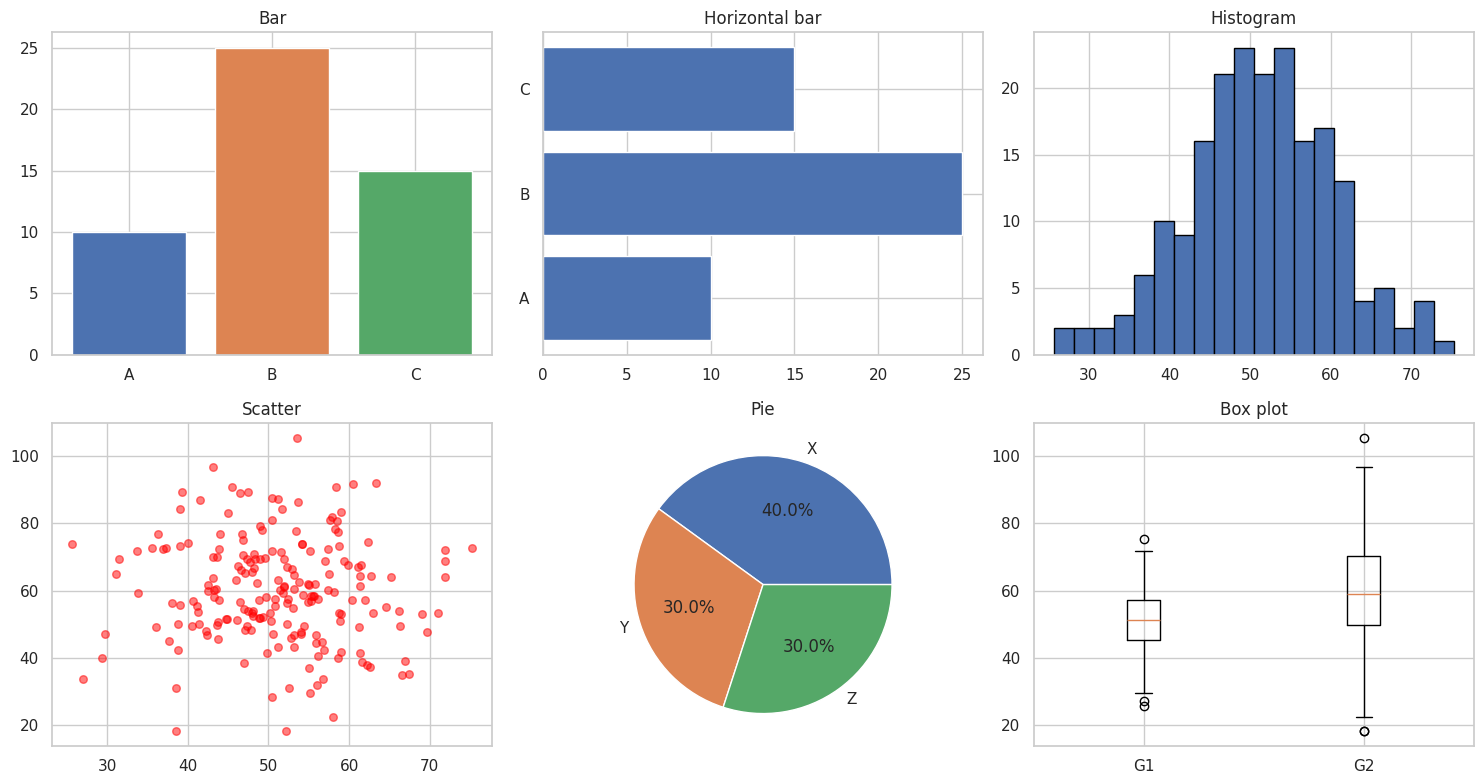

In [26]:
rng = np.random.RandomState(1)
data = rng.normal(50, 10, 200); data2 = rng.normal(60, 15, 200)
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
ax[0,0].bar(["A", "B", "C"], [10, 25, 15], color=["#4c72b0", "#dd8452", "#55a868"]); ax[0,0].set_title("Bar")
ax[0,1].barh(["A", "B", "C"], [10, 25, 15]); ax[0,1].set_title("Horizontal bar")
ax[0,2].hist(data, bins=20, edgecolor="black"); ax[0,2].set_title("Histogram")
ax[1,0].scatter(data, data2, c="red", s=30, alpha=0.5); ax[1,0].set_title("Scatter")
ax[1,1].pie([40, 30, 30], labels=["X", "Y", "Z"], autopct="%1.1f%%"); ax[1,1].set_title("Pie")
ax[1,2].boxplot([data, data2], labels=["G1", "G2"]); ax[1,2].set_title("Box plot")
plt.tight_layout(); plt.show()

## 8. Data Visualization: Seaborn

In [27]:
try:
    tips = sns.load_dataset("tips")
except Exception:                                   # offline fallback with similar structure
    r = np.random.RandomState(0); n = 244
    tips = pd.DataFrame({"total_bill": r.gamma(4, 5, n).round(2),
                         "sex": r.choice(["Male", "Female"], n), "smoker": r.choice(["Yes", "No"], n),
                         "day": r.choice(["Thur", "Fri", "Sat", "Sun"], n),
                         "time": r.choice(["Lunch", "Dinner"], n), "size": r.randint(1, 6, n)})
    tips["tip"] = (tips.total_bill * r.uniform(0.08, 0.25, n)).round(2)
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


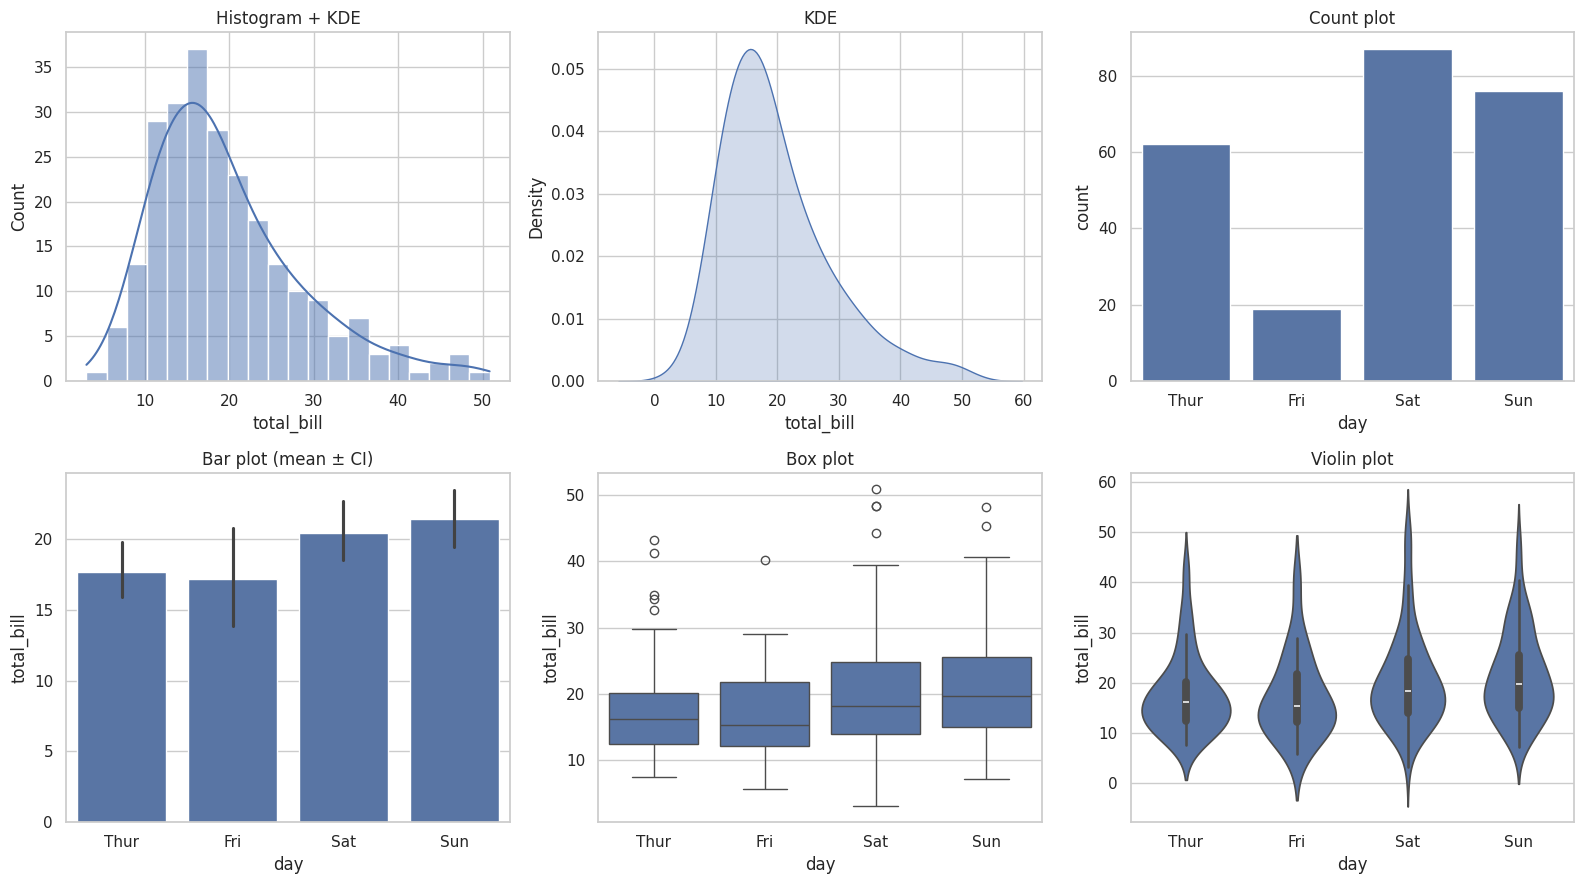

In [28]:
fig, ax = plt.subplots(2, 3, figsize=(16, 9))
sns.histplot(tips["total_bill"], kde=True, bins=20, ax=ax[0,0]).set_title("Histogram + KDE")
sns.kdeplot(tips["total_bill"], fill=True, ax=ax[0,1]).set_title("KDE")
sns.countplot(x="day", data=tips, ax=ax[0,2]).set_title("Count plot")
sns.barplot(x="day", y="total_bill", data=tips, ax=ax[1,0]).set_title("Bar plot (mean ± CI)")
sns.boxplot(x="day", y="total_bill", data=tips, ax=ax[1,1]).set_title("Box plot")
sns.violinplot(x="day", y="total_bill", data=tips, ax=ax[1,2]).set_title("Violin plot")
plt.tight_layout(); plt.show()

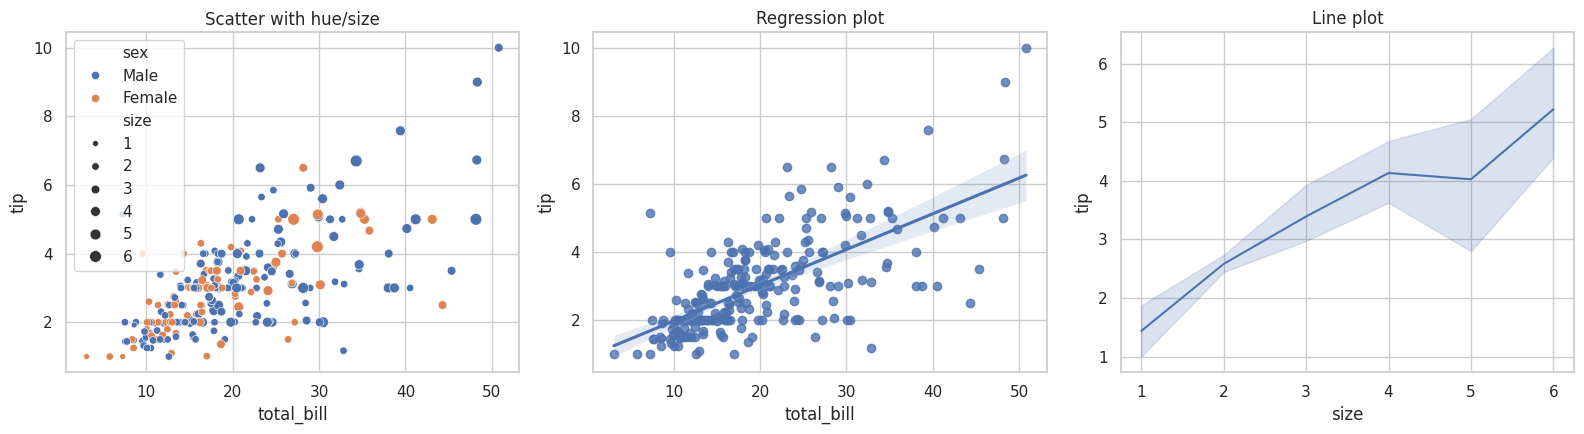

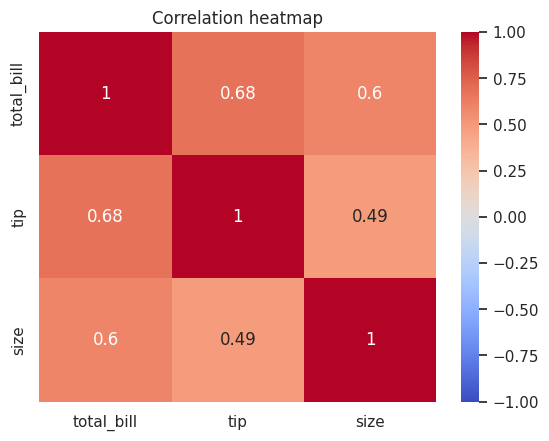

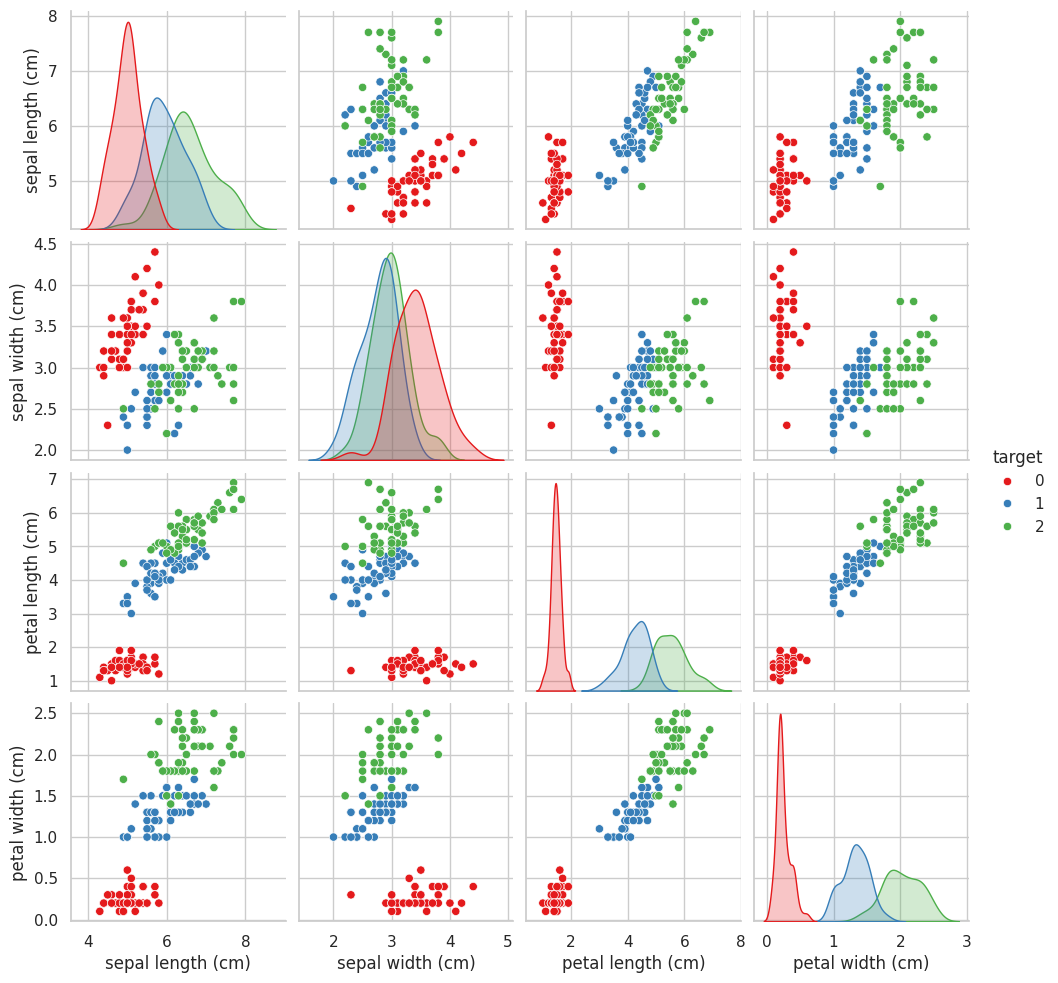

In [29]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
sns.scatterplot(x="total_bill", y="tip", hue="sex", size="size", data=tips, ax=ax[0]).set_title("Scatter with hue/size")
sns.regplot(x="total_bill", y="tip", data=tips, ax=ax[1]).set_title("Regression plot")
sns.lineplot(x="size", y="tip", data=tips, ax=ax[2]).set_title("Line plot")
plt.tight_layout(); plt.show()

sns.heatmap(tips.corr(numeric_only=True), annot=True, cmap="coolwarm", vmin=-1, vmax=1); plt.title("Correlation heatmap"); plt.show()
sns.pairplot(df_iris, hue="target", palette="Set1"); plt.show()

## 9. Mini End-to-End Project: Titanic (load → clean → EDA → visualize)

(891, 15)
age            177
embarked         2
deck           688
embark_town      2
dtype: int64
       survived  pclass     age   sibsp   parch    fare
count    775.00  775.00  775.00  775.00  775.00  775.00
mean       0.41    2.25   29.58    0.53    0.42   34.88
std        0.49    0.85   13.77    0.99    0.84   52.41
min        0.00    1.00    0.42    0.00    0.00    0.00
25%        0.00    1.00   21.00    0.00    0.00    8.05
50%        0.00    3.00   28.00    0.00    0.00   15.90
75%        1.00    3.00   36.00    1.00    1.00   34.20
max        1.00    3.00   80.00    8.00    6.00  512.33
sex
female    0.739726
male      0.215321
Name: survived, dtype: float64
pclass
1    0.633333
2    0.506098
3    0.259352
Name: survived, dtype: float64


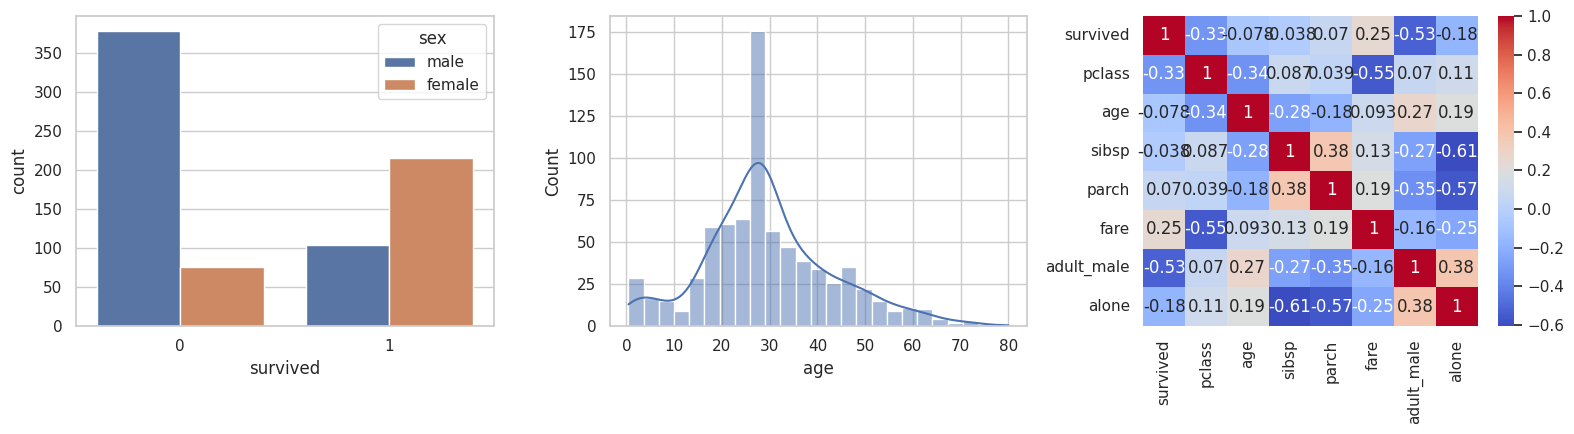

In [30]:
try:
    tt = sns.load_dataset("titanic")
except Exception as e:
    tt = None; print("Titanic dataset needs internet access:", e)

if tt is not None:
    print(tt.shape); print(tt.isnull().sum()[tt.isnull().sum() > 0])
    # clean
    tt["age"] = tt["age"].fillna(tt["age"].median())
    tt["embarked"] = tt["embarked"].fillna(tt["embarked"].mode()[0])
    tt = tt.drop(columns=["deck"]).drop_duplicates()
    # EDA
    print(tt.describe().round(2))
    print(tt.groupby("sex")["survived"].mean())
    print(tt.groupby("pclass")["survived"].mean())
    # visualize
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
    sns.countplot(x="survived", hue="sex", data=tt, ax=ax[0])
    sns.histplot(tt["age"], kde=True, ax=ax[1])
    sns.heatmap(tt.corr(numeric_only=True), annot=True, cmap="coolwarm", ax=ax[2])
    plt.tight_layout(); plt.show()

## 10. Practice Problem (from notes)
Data: 12, 15, 14, 10, 8, 12, 14, 13, 90 → mean, median, mode, IQR outliers.

In [31]:
p = pd.Series([12, 15, 14, 10, 8, 12, 14, 13, 90])
q1, q3 = p.quantile([.25, .75]); iqr = q3 - q1
print("mean =", round(p.mean(), 2), "| median =", p.median(), "| mode =", p.mode().tolist())
print(f"Q1={q1}, Q3={q3}, IQR={iqr}, fences=({q1-1.5*iqr}, {q3+1.5*iqr})")
print("Outliers:", p[(p < q1 - 1.5*iqr) | (p > q3 + 1.5*iqr)].tolist())

mean = 20.89 | median = 13.0 | mode = [12, 14]
Q1=12.0, Q3=14.0, IQR=2.0, fences=(9.0, 17.0)
Outliers: [8, 90]
